# Машинное обучение, ФКН ВШЭ

# Практическое задание 10. Обучение без учителя.

## Общая информация
Дата выдачи: 28.03.2024

Мягкий дедлайн: 15.04.2024 23:59 MSK

Жёсткий дедлайн: 21.04.2024 23:59 MSK

## Оценивание и штрафы

Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). 

Сдавать задание после указанного срока сдачи нельзя.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов (подробнее о плагиате см. на странице курса). Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке.

## Формат сдачи
Задания сдаются через систему anytask. Посылка должна содержать:
* Ноутбук homework-practice-10-Username.ipynb

Username — ваша фамилия на латинице

## О задании

В этом задании мы посмотрим на несколько алгоритмов кластеризации и применим их к географическим и текстовым данным. Также мы подробно остановимся на тематическом моделировании текстов, задаче обучения представлений и в каком-то смысле поработаем с semi-supervised learning. 



In [1]:
import pandas as pd
import numpy as np

np.random.seed(42)

**Задание 0 (1e-100 балла)**. Опишите свои ощущения от домашки по ЕМ-алгоритму (можно картинкой или мемом).

In [ ]:
# YOUR CODE HERE (ノಠ益ಠ)ノ彡┻━┻

## Часть 1. Кластеризация автобусных остановок

В этом задании мы сравним разные алгоритмы кластеризации для данных об автобусных остановках Москвы.

**Задание 1.1 (1 балл).** Реализуйте алгоритм спектральной кластеризации, который упоминался на лекции. Для этого разберитесь с кодом шаблона, данного ниже, и допишите недостающую функцию. Напомним, что для графа с матрицей смежности $W = \{w_{ij}\}_{i, j = 1 \dots \ell}$ лапласиан определяется как:

$$
L = D - W,
$$

где $D = \text{diag}(d_1, ..., d_{\ell}), d_i = \sum_{j=1}^{\ell} w_{ij}$.

In [2]:
from sklearn.base import ClusterMixin
from sklearn.cluster import KMeans
import numpy as np


class GraphClustering(ClusterMixin):
    def __init__(self, n_clusters=8, n_components=None, **kwargs):
        '''
        Spectral clustering algorithm
        param n_clusters: number of clusters to form
        param n_components: number of eigenvectors to use
        '''

        if n_components is None:
            n_components = n_clusters

        self.n_components = n_components
        self.kmeans = KMeans(n_clusters=n_clusters, **kwargs)

    def fit_predict(self, X, y=None):
        '''
        Perform spectral clustering from graph adjacency matrix
        and return vertex labels.
        param X: (n_samples, n_samples) - graph adjacency matrix
        return: (n_samples, ) - vertex labels
        '''

        eigenvectors = self._generate_eigenvectors(X)
        labels = self.kmeans.fit_predict(eigenvectors[:, 1:])
        return labels

    def _generate_eigenvectors(self, X):
        '''
        Compute eigenvectors for spectral clustering
        param X: (n_samples, n_samples) - graph adjacency matrix
        return: (n_samples, n_components) - eigenvectors
        '''
        # YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿

        L = np.diag(X.sum(axis=1))
        X = L - X

        a, b = np.linalg.eigh(X)
        vals = zip(a, np.arange(0, len(a), 1))
        vals = sorted(vals)
        idx = np.array(list(zip(*vals))).astype(int)
        idx = idx[1, :self.n_components]

        return b[:, idx]

Перед тем, как переходить к следующему заданию, протестируйте свое решение.

In [2]:
n_blocks, n_vertices = 10, 1000
block_vertices = n_vertices // n_blocks

X = np.zeros((n_vertices, n_vertices))
for i in range(0, n_vertices, block_vertices):
    X[i:i + block_vertices, i:i + block_vertices] = np.sqrt(i + 1)

graph_clustering = GraphClustering(n_clusters=n_blocks)
labels = graph_clustering.fit_predict(X)

true_labels = np.zeros(n_vertices, dtype=np.int32)
for i in range(0, n_vertices, block_vertices):
    true_labels[i:i + block_vertices] = labels[i]

assert labels.shape == (n_vertices, )
assert np.all(np.bincount(labels) == np.full(n_blocks, block_vertices))
assert np.all(labels == true_labels)
print("ok")

ok


Теперь можем приступить к работе с реальными данными. Скачайте файл с данными об остановках общественного транспорта **в формате .xlsx** по [ссылке](https://data.mos.ru/opendata/download/60464/1/201) (так гарантированно не возникнет проблем с парсингом файла) и загрузите таблицу в ноутбук. Если вдруг сайт Правительства Москвы сойдет с ума, то возьмите какую-нибудь версию данных [отсюда](https://data.mos.ru/opendata/7704786030-city-surface-public-transport-stops). Для удобства визуализации мы будем работать только с остановками в ЦАО.

In [ ]:
#No data :(
"""
data = pd.read_excel('transport.xlsx')
data = data[data.AdmArea_en == "Czentral`ny'j administrativny'j okrug"]
data = data.reset_index()
data.head()
"""

In [92]:
data = pd.read_excel('moscow_cao_stops.xlsx')
data = data.reset_index()
data = data.head(70)
data.head()

,index,stop_id,name,district,adm_area,latitude,longitude,routes_count
0,0,1001,Остановка Хамовники 1,Хамовники,Центральный административный округ,55.761862,37.594675,5
1,1,1002,Остановка Хамовники 2,Хамовники,Центральный административный округ,55.753874,37.615667,7
2,2,1003,Остановка Хамовники 3,Хамовники,Центральный административный округ,55.732323,37.649294,4
3,3,1004,Остановка Хамовники 4,Хамовники,Центральный административный округ,55.735715,37.632071,5
4,4,1005,Остановка Хамовники 5,Хамовники,Центральный административный округ,55.768796,37.646595,6


Воспользуемся библиотекой `folium` для визуализации данных.

In [93]:
import folium

map = folium.Map([55.75215, 37.61819], zoom_start=12)
for id, row in data.iterrows():
    folium.Circle([row.latitude, row.longitude],
                  radius=10).add_to(map)
map

**Задание 1.2 (1 балл).** Попробуем построить граф, в котором вершинами будут остановки. Как вы уже могли заметить, для каждой остановки указаны номера маршрутов, проходящих через неё. Логично соединить ребрами соседние остановки каждого маршрута. Однако мы не знаем, в каком порядке автобусы объезжают остановки. Но мы можем применить эвристический алгоритм, который восстановит нам порядок маршрутов:

* Для каждого маршрута выделим список всех остановок, через которые он проходит.
* Выберем начальную остановку маршрута как точку, наиболее удаленную от всех остальных остановок этого маршрута.
* Каждую следующую точку маршрута будем выбирать как самую близкую из оставшихся точек (не включенных в маршрут ранее).

Фактически, у нас получается жадное решение задачи коммивояжера. Когда мы отсортировали маршруты, можем построить по ним граф. Будем строить его по таким правилам:

* Между двумя остановками будет ребро, если они являются соседними хотя бы на одном маршруте. Вес ребра равен числу маршрутов, на которых остановки являются соседними.
* В графе не будет петель (то есть у матрицы смежности будет нулевая диагональ).

Реализуйте предложенный способ построения графа. Для этого рекомендуется воспользоваться шаблонами, приведенными ниже.

In [94]:
from math import radians, sin, cos, sqrt, atan2

def haversine(lat1, lon1, lat2, lon2):
    R = 6371
    lat1, lon1 = float(lat1), float(lon1)
    dlat = radians(lat2 - lat1)
    dlon = radians(lon2 - lon1)
    a = sin(dlat/2)**2 + cos(radians(lat1)) * cos(radians(lat2)) * sin(dlon/2)**2
    return R * 2 * atan2(sqrt(a), sqrt(1 - a))

In [3]:
def get_routes(data, n_routes=2000):
    '''
    Accumulate routes from raw data
    param data: pd.DataFrame - public transport stops data
    return: dict - unsorted stops ids for each route,
                   e.g. routes['A1'] = [356, 641, 190]
    '''
    # YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿
    routes = {}

    for i in range(n_routes):
        temp = pd.DataFrame()
        n_stops = np.random.randint(8, 15)
        stops = np.unique(np.random.randint(0, data.shape[0], size=n_stops))
        routes[f"A{i}"] = stops

    return routes


def sort_routes(data, routes):
    '''
    Sort routes according to the proposed algorithm
    param data: pd.DataFrame - public transport stops data
    param routes: dict - unsorted stops ids for each route
    return: dict - sorted stops ids for each route
    '''
    # YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿

    res_dict = {}
    cur = 0
    for key, val in routes.items():

        dist = lambda a, b : haversine(a["latitude"], a["longitude"], 
        b["latitude"], b["longitude"])

        res = []
        for i in val:
            sum = 0
            for j in val:
                if i == j:
                    continue
                else:
                    sum += dist(data.iloc[i], data.iloc[j])
            
            res.append(sum)
        res = np.array( list(zip(res, np.arange(0, len(res), 1).astype(int) )) )
        res = sorted(res, key=lambda x: x[0])

        start_idx = val[int(res[0][1])]

        val_copy = list(val.copy())
        val_copy.remove(start_idx)
        order = [start_idx]

        while len(val_copy) > 0:
            min_dist = 1e9
            vertex = 0
            for i in val_copy:
                cur_dist = dist(data.iloc[i], data.iloc[start_idx])
                if min_dist > cur_dist:
                    min_dist = cur_dist
                    vertex = i
            order.append(vertex)
            val_copy.remove(vertex)
            start_idx = vertex
        
        res_dict[f"A{cur}"] = order
        cur += 1
                
    return res_dict
    #raise NotImplementedError


def get_adjacency_matrix(data, sorted_routes):
    '''
    Compute adjacency matrix for sorted routes
    param data: pd.DataFrame - public transport stops data
    param sorted_routes: dict - sorted stops ids for each route
    return: (n_samples, n_samples) - graph adjacency matrix
    '''

    # YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿
    n = data.shape[0]
    res = np.full((n, n), 0)

    for key, val in sorted_routes.items():
        for j in range(1, len(val)):
            r, c = val[j-1], val[j]
            res[r][c] += 1
            res[c][r] += 1

    return res
    #raise NotImplementedError

In [98]:
routes = get_routes(data)
sorted_routes = sort_routes(data, routes)
adjacency_matrix = get_adjacency_matrix(data, sorted_routes)

Проверим, что маршруты получились адекватными. Для этого нарисуем их на карте.

In [99]:
map = folium.Map([55.75215, 37.61819], zoom_start=12)
for route_id in np.random.choice(list(sorted_routes.keys()), size=5):
    coords = data.loc[
        sorted_routes[route_id],
        ['latitude', 'longitude']
    ].values.tolist()
    folium.vector_layers.PolyLine(coords).add_to(map)

map

**Задание 1.3 (0 баллов)**. Реализуйте функцию `draw_clustered_map`, которая рисует карту центра Москвы с кластерами остановок, раскрашенными в разные цвета.

In [ ]:
def draw_clustered_map(data, labels):
    '''
    Create map with coloured clusters
    param data: pd.DataFrame - public transport stops data
    param labels: (n_samples, ) - cluster labels for each stop
    return: folium.Map - map with coloured clusters
    '''

    # YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿
    map = folium.Map([55.75215, 37.61819], zoom_start=12)

    n_cols = len(np.unique(labels))
    colors_rgb = np.random.randint(0, 255, size=(n_cols, 3))
    mask = (labels == -1)
    labels[mask] = n_cols - 1

    rgb_to_hex = lambda f : "#{:02x}{:02x}{:02x}".format(f[0], f[1], f[2])
    colors_hex = np.apply_along_axis(rgb_to_hex, axis=1, arr=colors_rgb)
    colors_hex = dict(list(zip(np.arange(0, len(colors_hex), 1), colors_hex)))

    for id, row in data.iterrows():
        folium.CircleMarker([row.latitude, row.longitude],
                    radius=3, color=f"{colors_hex[labels[id]]}").add_to(map)
    return map

**Задание 1.4 (1.5 балла)**. Примените алгоритмы кластеризации K-Means и DBSCAN из `sklearn` на координатах остановок, а также свою реализацию спектральной кластеризации на построенной выше матрице смежности. Визуализируйте результат кластеризации с помощью функции `draw_clustered_map`. Подберите параметры алгоритмов (`n_clusters` у K-Means, `eps` у DBSCAN, `n_clusters` и `n_components` у спектральной кластеризации) так, чтобы получить наиболее характерный для этих алгоритмов результат кластеризации (можете поэкспериментировать и оставить в ноутбуке картинки только для итоговых значений параметров, также обратите внимание на баланс объектов в кластерах). Не забудьте, что DBSCAN помечает некоторые точки как шумовые (можно раскрасить их в отдельный цвет).

In [203]:
# YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

data_latlon = data[ ["latitude", "longitude"] ]

s_scores = []
for k in range(2, 12):
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = km.fit_predict(data_latlon)
    score = silhouette_score(data_latlon, labels)
    s_scores.append(score)

best_k = np.arange(2, 12, 1)[np.argmax(s_scores)]

km_model = KMeans(n_clusters=best_k, random_state=42, n_init=20)
km_labels = km_model.fit_predict(data_latlon)

draw_clustered_map(data, km_labels)

In [221]:
from sklearn.cluster import DBSCAN

val_eps = np.linspace(1e-5, 1e-2, 500)
s_scores = []

for eps in val_eps:
    db = DBSCAN(eps=eps)
    labels = db.fit_predict(data_latlon)
    
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    if n_clusters > 1:
        mask = (labels != -1)
        if np.sum(mask) > min_samples:
            s = silhouette_score(data_latlon[mask], labels[mask])
            s_scores.append(s)
    else:
        s_scores.append(1e9)

best_eps = val_eps[np.argmax(s_scores)]

dbs_model = DBSCAN(eps=best_eps)
dbs_labels = dbs_model.fit_predict(data_latlon)

draw_clustered_map(data, dbs_labels)

In [218]:
# YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿

val_nclust = np.arange(2, 10, 1)
val_ncomps = np.arange(2, 10, 1)
s_scores = []


model = GraphClustering()

for n_clust in val_nclust:
    for n_comps in val_ncomps:
        model = GraphClustering(n_clusters=n_clust, n_components=n_comps)
        labels = model.fit_predict(adjacency_matrix)
        s = silhouette_score(data_latlon[mask], labels[mask])
        s_scores.append(s)

best_params = val_eps[np.argmax(s_scores)]
r, c = int(best_params // 8 + 2), int(best_params % 8 + 2)

gc_model = GraphClustering(n_clusters=r, n_components=c)
gc_labels = gc_model.fit_predict(adjacency_matrix)

draw_clustered_map(data, gc_labels)

Проинтерпретируйте полученные результаты. Чем отличаются разбиения на кластеры, получаемые разными алгоритмами? Какие плюсы и минусы есть у каждого алгоритма? Какой алгоритм кажется вам наиболее подходящим для кластеризации остановок?

**Ответ:** KMeans делит остановки на примерно одинаковые по площади сектора, в то время как DBScan выделяет сгустки остановок как отдельные сектора. Так как остановки находятся достаточно близко друг к другу, DBScan обозначает их как единый кластер. Спектральная кластеризация учитывает связность остановок через граф, поэтому даже находящиеся рядом остановки могут иметь разные метки.

Плюсы и минусы:

K-means: быстрый и равномерно балансирует классы, но чувствителен к выбросам

DBScan: не требует задавать количество кластеров, чувствителен к выбору eps

GraphClustering: работает с топологией графа, медленно работает

## Часть 2. Тематическое моделирование текстов

В этой части мы познакомимся с одной из самых популярных задач обучения без учителя &mdash; с задачей тематического моделирования текстов. Допустим, нам доступна некоторая коллекция документов без разметки, и мы хотим автоматически выделить несколько тем, которые встречаются в документах, а также присвоить каждому документу одну (или несколько) тем. Фактически, мы будем решать задачу, похожую на кластеризацию текстов: отличие в том, что нас будет интересовать не только разбиение текстов на группы, но и выделение ключевых слов, определяющих каждую тему.

Мы будем работать с новостными статьями BBC за 2004-2005 годы. Скачайте данные по [ссылке](https://www.kaggle.com/hgultekin/bbcnewsarchive).

In [3]:
data = pd.read_csv('./bbc-news-data.csv', sep='\t')
data.sample(5)

,category,filename,title,content
414,business,415.txt,UK house prices dip in November,"UK house prices dipped slightly in November, ..."
420,business,421.txt,LSE 'sets date for takeover deal',The London Stock Exchange (LSE) is planning t...
1644,sport,332.txt,Harinordoquy suffers France axe,Number eight Imanol Harinordoquy has been dro...
416,business,417.txt,Barclays shares up on merger talk,Shares in UK banking group Barclays have rise...
1232,politics,337.txt,Campaign 'cold calls' questioned,Labour and the Conservatives are still teleph...


Как вы могли заметить, данные уже содержат разметку по тематике (колонка category). В этой части мы забудем, что она есть, и будем работать только с текстовыми данными. Проведем предобработку текста, состоящую из следующих пунктов:

* Объединим заголовок и содержание статьи в одно поле.
* Приведем текст к нижнему регистру, разобьем его на токены.
* Оставим только буквенные слова (удалив, таким образом, пунктуацию и числа).
* Применим лемматизацию.
* Удалим стоп-слова.


In [4]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

nltk.download('punkt_tab', raise_on_error=True)
nltk.download('wordnet', raise_on_error=True)
nltk.download('stopwords', raise_on_error=True)

stop_words = set(stopwords.words('english') + ['ha', 'wa', 'say', 'said'])
lemmatizer = WordNetLemmatizer()

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\alim\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\alim\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\alim\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [5]:
def preprocess(text):
    text = list(filter(str.isalpha, word_tokenize(text.lower())))
    text = list(lemmatizer.lemmatize(word) for word in text)
    text = list(word for word in text if word not in stop_words)
    return ' '.join(text)

In [6]:
data['raw_text'] = data.apply(lambda row: row.title + row.content, axis=1)
data['text'] = data.apply(lambda row: preprocess(row.raw_text), axis=1)

Для визуализации частот слов в текстах мы будем использовать [облака тегов](https://en.wikipedia.org/wiki/Tag_cloud).

In [17]:
from wordcloud import WordCloud

def draw_wordcloud(texts, max_words=1000, width=1000, height=500):
    wordcloud = WordCloud(background_color='white', max_words=max_words,
                          width=width, height=height)
    
    joint_texts = ' '.join(list(texts))
    wordcloud.generate(joint_texts)
    return wordcloud.to_image()

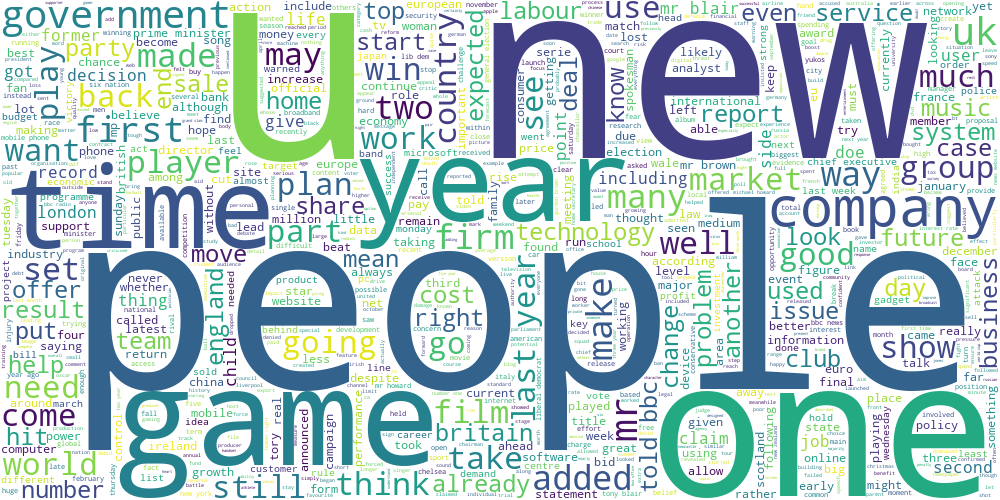

In [10]:
draw_wordcloud(data.text)

**Задание 2.1 (1 балл).** Обучите алгоритм K-Means на tf-idf представлениях текстов. При обучении tf-idf векторайзера рекомендуется отбрасывать редко встречающиеся слова, а также воздержитесь от использования N-грамм. Возьмите не очень большое число кластеров, чтобы было удобно интерпретировать получившиеся темы (например, `n_clusters` = 8). Постройте облака тегов для текстов из разных кластеров. Получились ли темы интерпретируемыми? Попробуйте озаглавить каждую тему.

**Ответ:** Облака тегов получились интерпретируемыми, первое изображения относится к фильмам, тогда как второе к политике

In [8]:
# YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(min_df=4) #At least in 4 docs
X = vectorizer.fit_transform(data["text"].values)

model_km = KMeans(n_clusters=8, n_init=20)
labels = model_km.fit_predict(X)

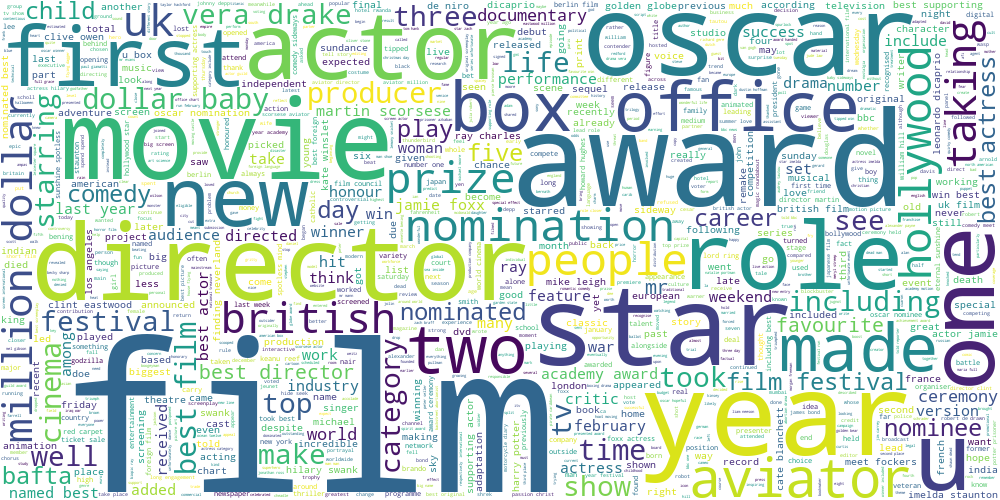

In [32]:
mask = (labels == 0)
texts = data["text"][mask]
draw_wordcloud(texts)

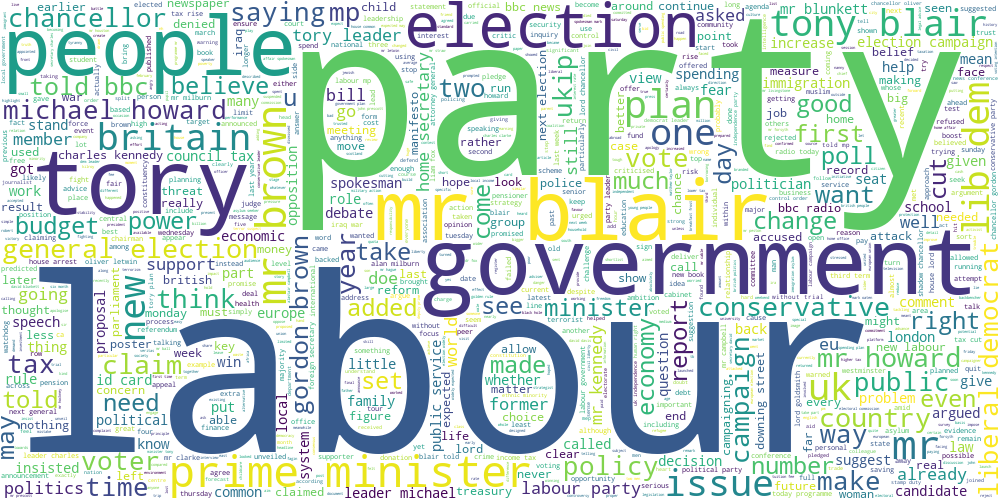

In [33]:
mask = (labels == 1)
texts = data["text"][mask]
draw_wordcloud(texts)

**Задание 2.2 (0.5 балла).** Попробуем другой способ выделить ключевые слова для каждой темы. Помимо непосредственного разбиения объектов алгоритм K-Means получает центр каждого кластера. Попробуйте взять центры кластеров и посмотреть на слова, для которых значения соответствующих им признаков максимальны. Согласуются ли полученные слова с облаками тегов из прошлого задания?

**Ответ:** Согласуются, но могут перескаться. Слово мистер являются ключевым словом для нескольких тем одномвременно.

In [37]:
# YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿
idx = np.argmax(model_km.cluster_centers_, axis=1)
print(vectorizer.get_feature_names_out()[idx])

['film' 'mr' 'game' 'mobile' 'mr' 'music' 'yukos' 'growth']


**Задание 2.3 (1.5 балла).** В первой части мы сравнили три разных алгоритма кластеризации на географических данных. Проделаем то же самое для текстовых данных (в качестве признакого описания снова используем tf-idf). Получите три разбиения на кластеры с помощью алгоритмов K-Means, DBSCAN и спектральной кластеризации (на этот раз воспользуйтесь реализацией из `sklearn`). Для K-Means и спектральной кластеризации возьмите одинаковое небольшое число кластеров, подберите параметр `eps` метода DBSCAN так, чтобы получить приблизительно такое же число кластеров.

Далее, обучите двухмерные t-SNE представления над tf-idf признаками текстов. Визуализируйте эти представления для каждого алгоритма, раскрасив каждый кластер своим цветом. Лучше всего расположить визуализации на одном графике на трех разных сабплотах. Не забудьте, что DBSCAN помечает некоторые точки как шумовые (можно раскрасить их в отдельный цвет).

In [16]:
# YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿
from sklearn.cluster import DBSCAN, SpectralClustering
from sklearn.metrics import silhouette_score

scores = []
for n_clusters in range(2, 11):
    model_km = KMeans(n_clusters=n_clusters)
    labels = model_km.fit_predict(X)
    score = silhouette_score(X, labels)
    scores.append(score)

print("Best n_clusters:", np.argmax( np.array(scores) ) )

Best n_clusters: 6


In [88]:
def draw_multiple_wordclouds(text : np.array, axes, labels : np.array, 
max_words=100, width=600, height=600, include_noise = False):
    for i, ax in enumerate(axes):

        cur_label = i
        if include_noise:
            cur_label -= 1

        mask = (labels == cur_label)

        if mask.sum() == 0:
            return

        wordcloud = WordCloud(background_color='white', max_words=max_words,
                          width=width, height=height, colormap="viridis")
        joint_texts = ' '.join(text[mask])
        wordcloud.generate(joint_texts)

        ax.imshow(wordcloud.to_image(), interpolation="bilinear")
        ax.set_title(f"Label = {cur_label}", fontsize=16, fontweight="bold", pad=12)
        ax.axis("off")

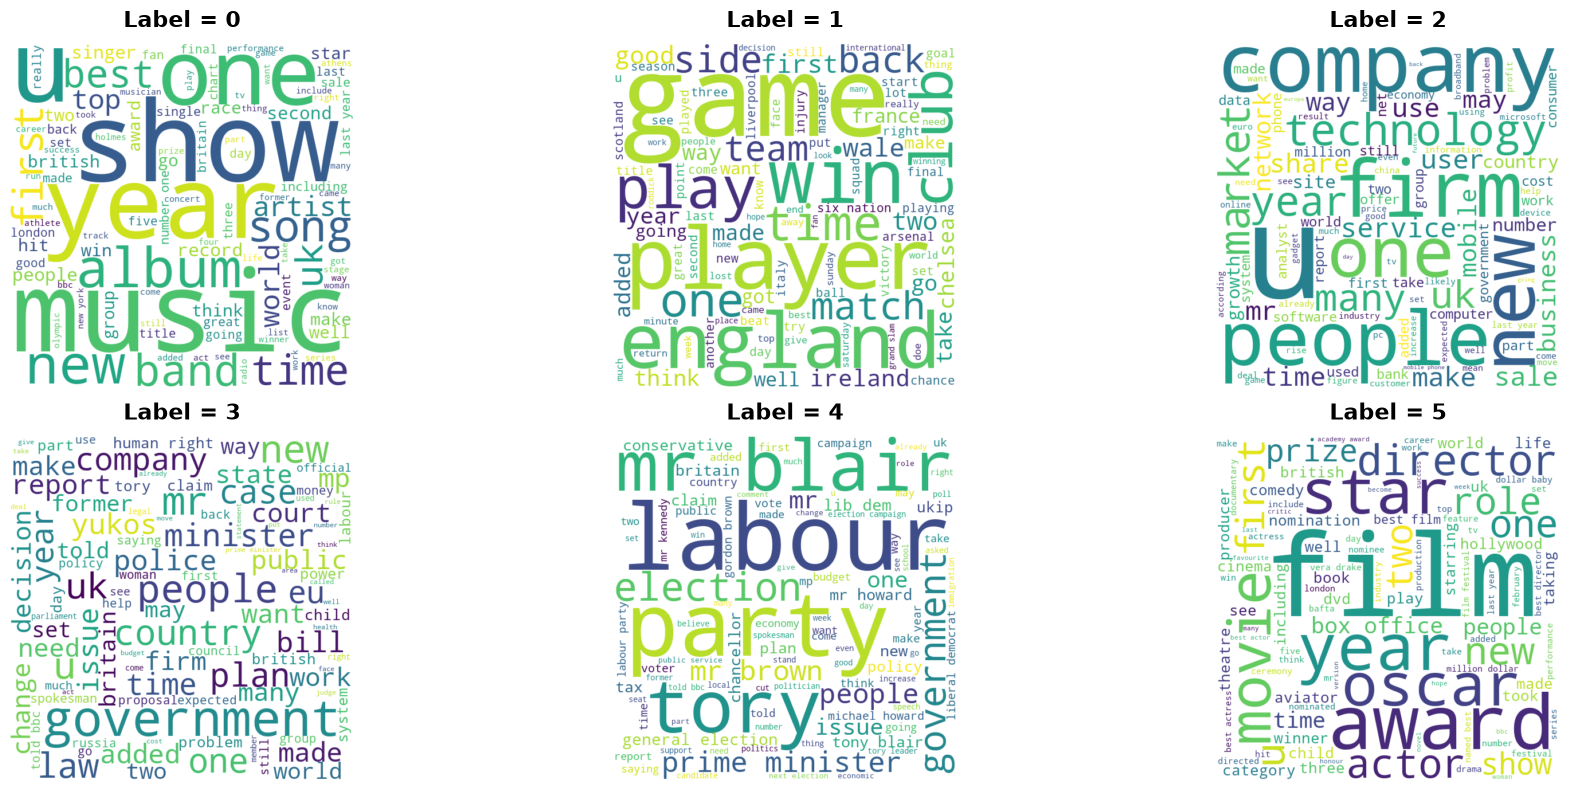

2    775
1    476
3    359
0    259
4    181
5    175
Name: count, dtype: int64


In [99]:
n_clusters = 6
model_km = KMeans(n_clusters=n_clusters)
labels = model_km.fit_predict(X)
fig, ax = plt.subplots(2, 3, figsize=(20, 8))


draw_multiple_wordclouds(data["text"].values, ax.flatten(), labels)
plt.tight_layout()
plt.show()

test = pd.Series(labels)
print(test.value_counts())

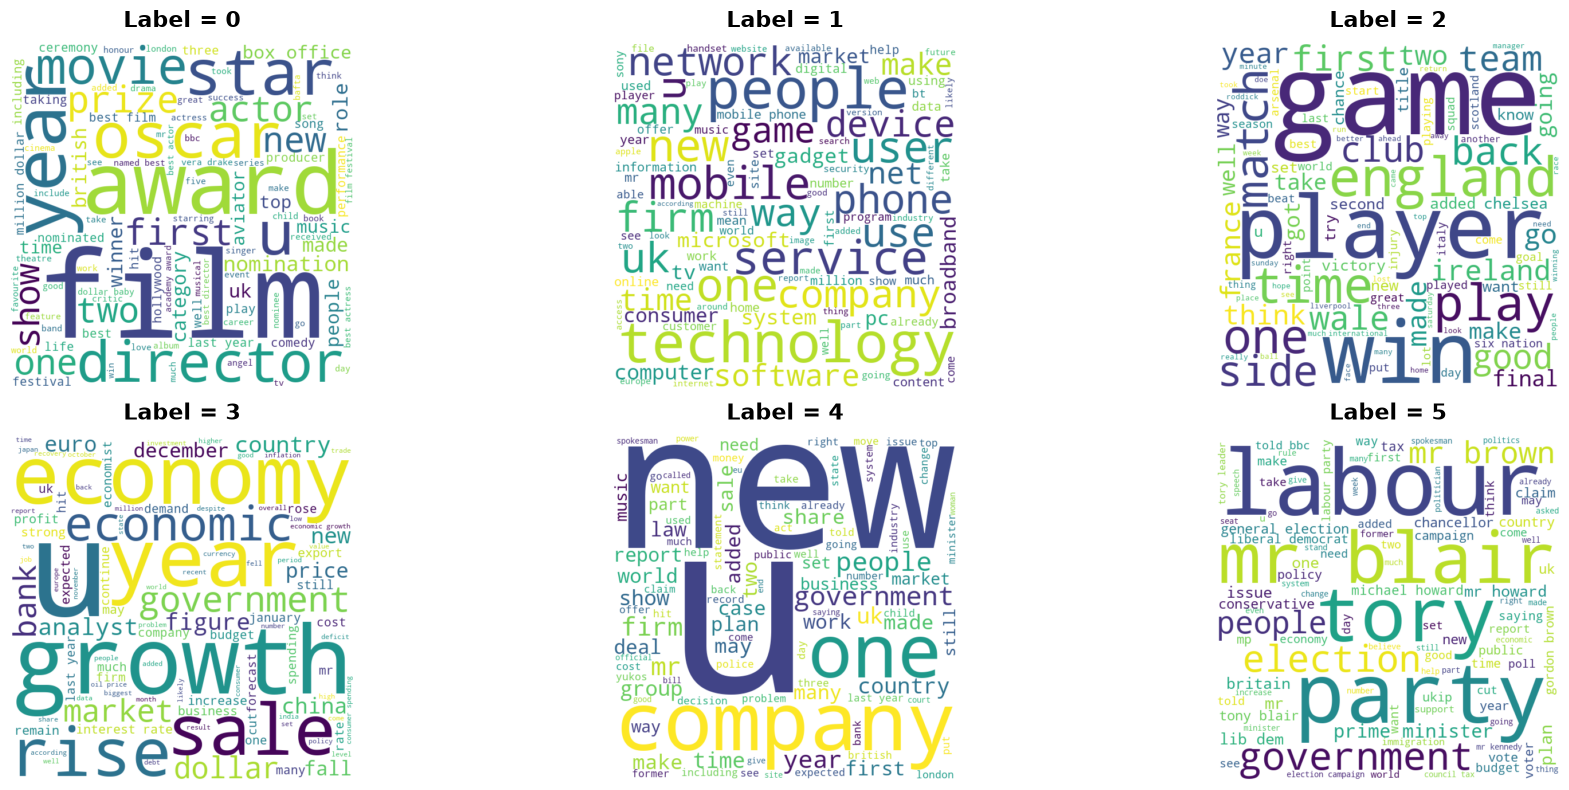

4    915
2    493
1    272
5    196
3    181
0    168
Name: count, dtype: int64


In [100]:
model_s = SpectralClustering(n_clusters=n_clusters)
labels = model_s.fit_predict(X)
fig, ax = plt.subplots(2, 3, figsize=(20, 8))

draw_multiple_wordclouds(data["text"].values, ax.flatten(), labels)
plt.tight_layout()
plt.show()

test = pd.Series(labels)
print(test.value_counts())

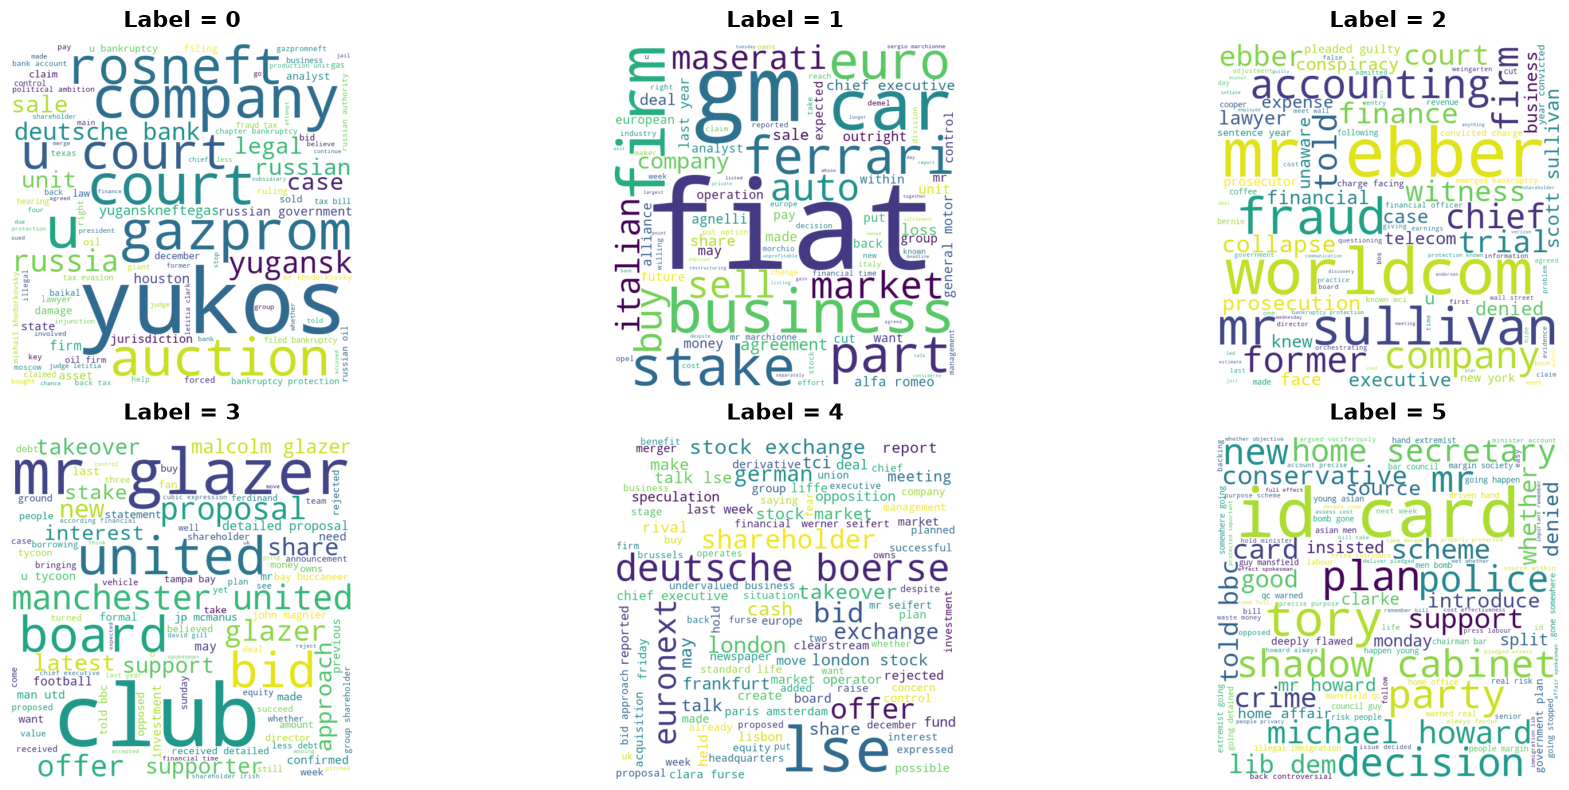

-1    2187
 0       9
 4       8
 3       6
 1       5
 2       5
 5       5
Name: count, dtype: int64


In [101]:
all_eps = np.logspace(-1, 2, 90)
best_eps = 0
best_dist = 1000
best_score = -1000

for eps in all_eps:
    model_db = DBSCAN(eps=eps)
    labels = model_db.fit_predict(X)
    n_labels = len(np.unique(labels))
    dist = abs(n_clusters - n_labels)

    if n_labels > 1 and dist <= best_dist:
        score = silhouette_score(X, labels)
        if dist < best_dist:
            best_dist = dist
            best_eps = eps
            best_score = score
        else:
            if score > best_score:
                best_score = score
                best_eps = eps

model_db = DBSCAN(best_eps)
labels = model_db.fit_predict(X)
fig, ax = plt.subplots(2, 3, figsize=(20, 8))

draw_multiple_wordclouds(data["text"].values, ax.flatten(), labels, include_noise=False)
plt.tight_layout()
plt.show()

test = pd.Series(labels)
print(test.value_counts())

In [163]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2)
t_vectorizer = TfidfVectorizer(min_df=100) #To speed up tsne
X = t_vectorizer.fit_transform(data["text"].values)

emb = tsne.fit_transform(X)

print(emb.shape)

(2225, 2)


<Axes: >

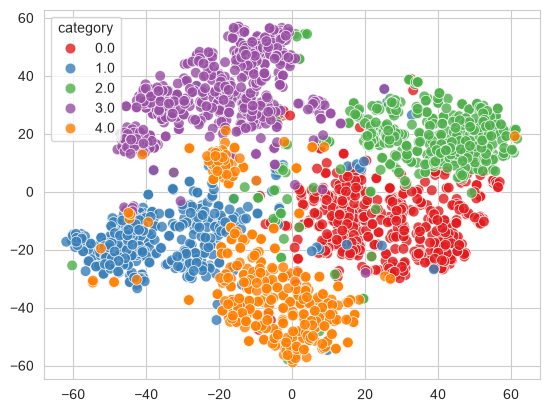

In [ ]:
import seaborn as sns
sns.set_style("whitegrid")

sns.scatterplot(
    x=emb[:, 0], 
    y=emb[:, 1], 
    hue=data["category"],
    palette="Set1", 
    alpha=0.8,
    s=60
)

Прокомментируйте получившиеся результаты. Какой баланс кластеров получился у разных методов? Соотносятся ли визуализации для текстов с визуализациями для географических данных?

**Ответ:** DBScan помечяет большинство точек шумовыми из-за низкой плотности в пространстве. KM в плане баланса классов отработал лучше чем SC. Визуализации для текстов и геоданных не соотносятся, так как многие точки лежат внутри чужих классов.

**Задание 2.4 (1.5 балла).** Обучите модель латентного размещения Дирихле. Не забудьте, что она работает с мешком слов, а не с tf-idf признаками. Придумайте, как превратить распределение тем для текста в номер его кластера. Возьмите параметр `n_components` в 2-3 раза больше, чем число кластеров для K-Means. Получились ли темы более узкими от такого нововведения? Постройте облака тегов для нескольких наиболее удачных тем.

**Ответ:** Да, увеличение количества тем сделало каждую тему более узкой.

In [108]:
# YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

vectorizer = CountVectorizer(max_features=7000, ngram_range=(2, 2))
Xb = vectorizer.fit_transform(data["text"])

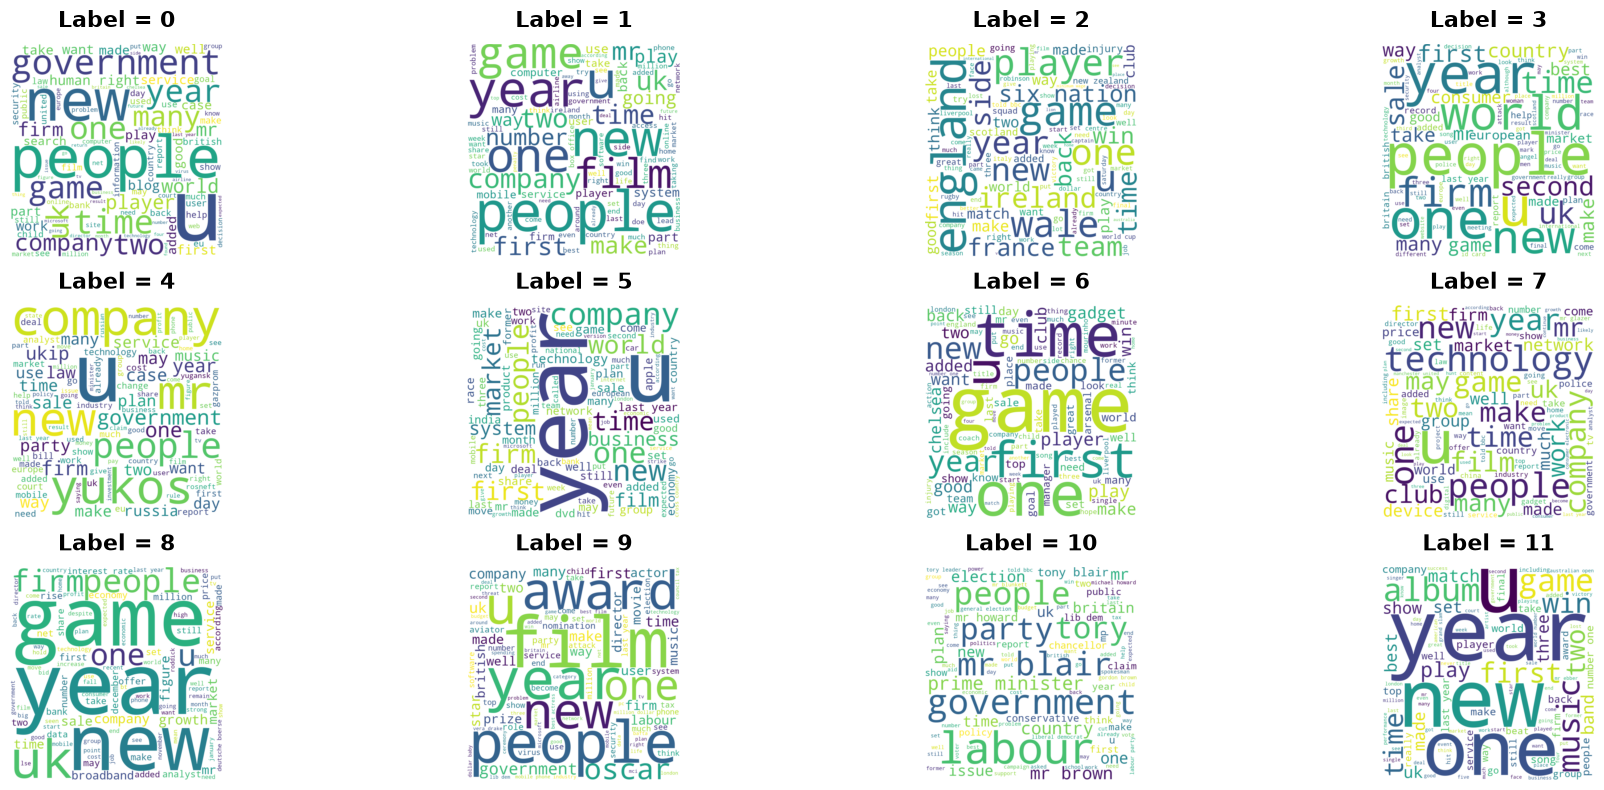

In [118]:
model_lda = LatentDirichletAllocation(n_components=n_clusters * 2)
res = model_lda.fit_transform(Xb)
labels = np.argmax(res, axis=1)

fig, ax = plt.subplots(3, 4, figsize=(20, 8))
draw_multiple_wordclouds(data["text"], ax.flatten(), labels, width=800, height=800)
plt.tight_layout()
plt.show()

## Часть 3. Transfer learning для задачи классификации текстов

**Задание 3.1 (0.5 балла).** Вспомним, что у нас есть разметка для тематик статей. Попробуем обучить классификатор поверх unsupervised-представлений для текстов. Рассмотрите три модели:

* Логистическая регрессия на tf-idf признаках
* K-Means на tf-idf признаках + логистическая регрессия на расстояниях до центров кластеров
* Латентное размещение Дирихле + логистическая регрессия на вероятностях тем

Разделите выборку на обучающую и тестовую, замерьте accuracy на обоих выборках для всех трех моделей. Параметры всех моделей возьмите равными значениям по умолчанию.

In [128]:
from sklearn.preprocessing import OrdinalEncoder

ord = OrdinalEncoder()
data["category"] = ord.fit_transform(data[["category"]])

In [156]:
# YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

y = data["category"]
model = LogisticRegression()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)
model.fit(X_train, y_train)
y_preds = model.predict(X_test)
acc = accuracy_score(y_test, y_preds)
print(f"Logreg acc(tf-idf): {acc}")


model_km = KMeans(n_clusters=4)
model_km.fit(X_train)
model = LogisticRegression()
model.fit( model_km.transform(X_train), y_train )
y_preds = model.predict( model_km.transform(X_test) )
acc = accuracy_score(y_test, y_preds)
print(f"Logreg acc(k-means on tf-idf): {acc}")


model = LogisticRegression()
model_lda = LatentDirichletAllocation(n_components=4)
model.fit( model_lda.fit_transform(X_train), y_train )
y_preds = model.predict( model_lda.transform(X_test) )
acc = accuracy_score(y_test, y_preds)
print(f"Logreg acc(LDA on tf-idf): {acc}")

Logreg acc(tf-idf): 0.9670658682634731
Logreg acc(k-means on tf-idf): 0.6916167664670658
Logreg acc(LDA on tf-idf): 0.49700598802395207


У какой модели получилось лучшее качество? С чем это связано?

**Ответ:** У модели обученной на tf-idf, так как tf-idf имеет наибольшее количество фичей (около 9000). С другой стороны km и lda дали отличный результат несмотря на то, что после кодирования они имеют всего 4 фичи, в особенности km + logreg с accuracy ~ 0.7.

**Задание 3.2 (1.5 балла).** Теперь просимулируем ситуацию слабой разметки, которая часто встречается в реальных данных. Разделим обучающую выборку в пропорции 5:65:30. Будем называть части, соответственно, размеченный трейн, неразмеченный трейн и валидация.

Все unsupervised-алгоритмы (векторайзеры и алгоритмы кластеризации) запускайте на всем трейне целиком (размеченном и неразмеченном, суммарно 70%), а итоговый классификатор обучайте только на размеченном трейне (5%). Подберите гиперпараметры моделей по качеству на валидации (30%), а затем оцените качество на тестовой выборке (которая осталась от прошлого задания). Не скромничайте при подборе числа кластеров, сейчас нас интересует не интерпретируемое разбиение выборки, а итоговое качество классификации. 

In [157]:
# YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿
X_train_full, X_test_full = X_train.copy(), X_test.copy()
X_train, X_train_val, y_train, y_train_val = train_test_split(X_train, y_train, test_size=0.07)

model = LogisticRegression()
model.fit(X_train_val, y_train_val)
y_preds = model.predict(X_test)
acc = accuracy_score(y_test, y_preds)
print(f"Logreg acc(tf-idf): {acc}")


model_km = KMeans(n_clusters=20)
model_km.fit(X_train_full)
model = LogisticRegression()
model.fit( model_km.transform(X_train_val), y_train_val )
y_preds = model.predict( model_km.transform(X_test) )
acc = accuracy_score(y_test, y_preds)
print(f"Logreg acc(k-means on tf-idf): {acc}")


model = LogisticRegression()
model_lda = LatentDirichletAllocation(n_components=20)
model_lda.fit(X_train_full)
model.fit( model_lda.transform(X_train_val), y_train_val )
y_preds = model.predict( model_lda.transform(X_test) )
acc = accuracy_score(y_test, y_preds)
print(f"Logreg acc(LDA on tf-idf): {acc}")


Logreg acc(tf-idf): 0.6931137724550899
Logreg acc(k-means on tf-idf): 0.31736526946107785
Logreg acc(LDA on tf-idf): 0.37425149700598803


Как изменились результаты по сравнению с обучением на полной разметке? Сделайте выводы.

**Ответ:** Результат ухудшился, так как модель теряет часть информации с метками(размеченный трейн уменьшился), а также информацию которая теряется в процессе обработки (km, lda).

## Бонус

**Задание 4 (1 балл)**. Разберитесь с semi-supervised методами, которые реализованы в `sklearn` и примените их к заданию 3.2. Получилось ли добиться лучшего качества? Сделайте выводы.

In [ ]:
# YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿

**Задание 5 (1 балл)**. На занятиях мы обсуждали, что метрика [BCubed](https://www.researchgate.net/profile/Julio-Gonzalo-2/publication/225548032_Amigo_E_Gonzalo_J_Artiles_J_et_alA_comparison_of_extrinsic_clustering_evaluation_metrics_based_on_formal_constraints_Inform_Retriev_12461-486/links/0c96052138dbb99740000000/Amigo-E-Gonzalo-J-Artiles-J-et-alA-comparison-of-extrinsic-clustering-evaluation-metrics-based-on-formal-constraints-Inform-Retriev-12461-486.pdf) хорошо подходит для сравнения алгоритмов кластеризации, если нам известно настоящее разделение на кластеры (gold standard). Реализуйте подсчет метрики BCubed и сравните несколько алгоритмов кластеризации на текстовых данных из основного задания. В качестве gold standard используйте разметку category.

In [ ]:
# YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿

**Задание 6 (2 баллa)**. Спектральная кластеризация, по сути, является обычной кластеризацией KMeans поверх эмбеддингов объектов, которые получаются из лапласиана графа. А что, если мы попробуем построить эмбеддинги каким-нибудь другим способом? В этом задании мы предлагаем вам проявить немного фантазии. Возьмите какие-нибудь данные высокой размерности, чтобы задача обучения эмбеддингов имела смысл (например, картинки или тексты, желательно выбрать что-нибудь оригинальное). Придумайте или найдите какой-нибудь метод обучения эмбеддингов, примените его к данным и кластеризуйте полученные представления. Если чувствуете в себе достаточно силы, можете попробовать что-нибудь нейросетевое. Сравните ваш подход с базовыми алгоритмами кластеризации, которое мы рассмотрели в основном задании, не забывайте про визуализации! Ключевые слова для вдохновения: ***KernelPCA***, ***UMAP***, ***autoencoders***, ***gensim***. 

In [ ]:
# YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿

**Задание 7 (1 балл)**. Наконец, ставший ежегодной традицией социализационный бонус. Мы поощряем не только предметное, но и духовное развитие. Поэтому, чтобы заработать балл за это задание, сходите на какую-нибудь выставку или в музей, напишите небольшой отчетик о ваших впечатлениях и добавьте фотопруфы в ноутбук при сдаче. Можете объединиться с одногруппниками/однокурсниками, а также пригласить ассистентов/преподавателей, они тоже будут рады выбраться куда-нибудь. Для вдохновения приведем ссылку на актуальные выставки [новой](https://www.youtube.com/watch?v=dQw4w9WgXcQ&ab) и [старой Третьяковки](https://www.youtube.com/watch?v=xm3YgoEiEDc) (но совсем не обязательно посещать именно их).

In [ ]:
# YOUR CODE HERE (ノಠ益ಠ)ノ彡┻━┻